# Preprocessing Steps

This notebook outlines the data preprocessing pipeline, detailing the steps taken to clean, transform, and prepare the raw dataset for machine learning modeling.

The code below serves as a setup code block to load all the libraries and initialises the directory paths:

In [17]:
# Imports
import ast
import os
import re
import warnings
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed
from pyBKT.models import Model
from sklearn.preprocessing import PowerTransformer

# Initialize the directory paths
ROOT_DIRECTORY = "../dataset/"
CLEANED_DIRECTORY = ROOT_DIRECTORY + "0_cleaned/"
LOCATION_1 = ROOT_DIRECTORY + "1_aug_to_oct/"
LOCATION_2 = ROOT_DIRECTORY + "2_nov_to_jan/"
LOCATION_3 = ROOT_DIRECTORY + "3_feb_to_apr/"
LOCATION_4 = ROOT_DIRECTORY + "4_may_to_june/"

# Seed to support reproducibility
RANDOM_STATE = 42

## Step 1: Data Retrieval and Feature Removal

We shall first scrutinize all dataset details, then select the appropriate one to be used in this project.

### 1.1 Dataset File Size and Row Number Review

Note: Due to their large size of the dataset, all datasets are removed to save space. The results obtained when all the datasets are loaded are shown here, and the code is commented out to avoid errors when the notebook is re-executed.

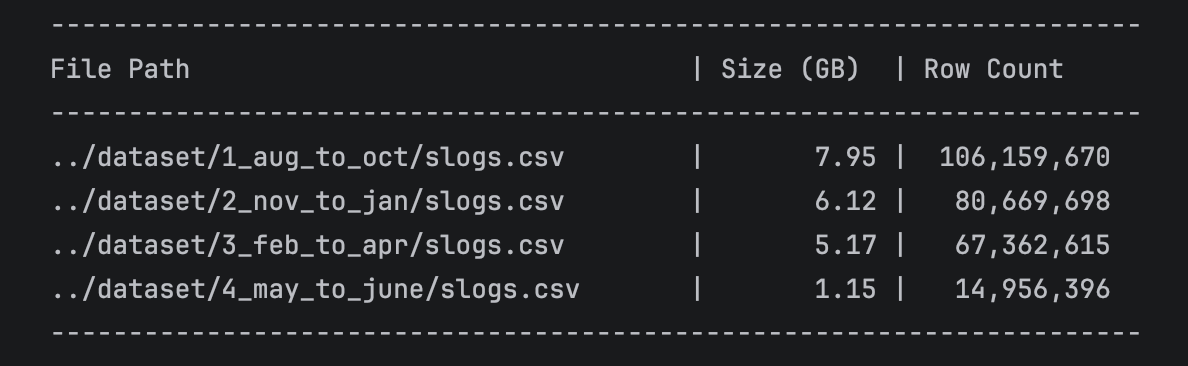

In [ ]:
'''
# Retrieve all SLOGS file paths
slogs_paths = [
    LOCATION_1 + "slogs.csv",
    LOCATION_2 + "slogs.csv",
    LOCATION_3 + "slogs.csv",
    LOCATION_4 + "slogs.csv"
]

# Print table headers
print("-" * 70)
print(f"{'File Path':<40} | {'Size (GB)':<10} | {'Row Count':<12}")
print("-" * 70)

# Go through each SLOGS table
for path in slogs_paths:

    # Calculate the size of the SLOGS table
    file_size_bytes = os.path.getsize(path)
    file_size_gb = file_size_bytes / (1024 * 1024 * 1024)

    # Calculate the number of rows in each SLOGS table. We filter the table to one column to save memory
    row_count = len(pd.read_csv(path, usecols=["log_id"]))

    # Print the details
    print(f"{path:<40} | {file_size_gb:>10.2f} | {row_count:>12,}")

print("-" * 70)
'''

----------------------------------------------------------------------
File Path                                | Size (GB)  | Row Count   
----------------------------------------------------------------------
../dataset/1_aug_to_oct/slogs.csv        |       7.95 |  106,159,670
../dataset/2_nov_to_jan/slogs.csv        |       6.12 |   80,669,698
../dataset/3_feb_to_apr/slogs.csv        |       5.17 |   67,362,615
../dataset/4_may_to_june/slogs.csv       |       1.15 |   14,956,396
----------------------------------------------------------------------


### 1.2 Extract SLOGS and PDETS for May-June

In [19]:
# ===== Note: This code is commented as the May-June dataset is removed. =====
# Retrieve the SLOGS table for May-June
# student_log_df = pd.read_csv(LOCATION_4 + "slogs.csv")
# question_attr_df = pd.read_csv(LOCATION_4 + "pdets.csv")

# ===== Instead, we can read from the extracted parquet files to view the contents =====
student_log_df = pd.read_parquet(CLEANED_DIRECTORY + "slogs.parquet")
question_attr_df = pd.read_parquet(CLEANED_DIRECTORY + "pdets.parquet")

# Output details inside both tables
print("Preview of SLOGS (4_may_to_june):")
display(student_log_df.head())

print("\nPreview of PDETS (4_may_to_june):")
display(question_attr_df.head())

# Save the dataset into the cleaned folder as parquet for further preprocessing
student_log_df.to_parquet(CLEANED_DIRECTORY + "slogs.parquet", index=False)
question_attr_df.to_parquet(CLEANED_DIRECTORY + "pdets.parquet", index=False)

Preview of SLOGS (4_may_to_june):


,log_id,student_id,assignment_id,problem_id,action,timestamp
0,16062814,740890,1397084,NaN,assignment_started,2021-05-01 13:48:08.252000+00:00
1,16062814,740890,1397084,"1,220,201.00000",problem_started,2021-05-01 13:48:08.687000+00:00
2,16062814,740890,1397084,"1,220,201.00000",wrong_response,2021-05-01 13:48:37.798000+00:00
3,16062884,802471,1399980,NaN,assignment_started,2021-05-01 14:50:45.223000+00:00
4,16062884,802471,1399980,"1,762,838.00000",problem_started,2021-05-01 14:50:45.901000+00:00



Preview of PDETS (4_may_to_june):


,problem_id,content_source,skills,problem_type,tutoring_types,student_answer_count,mean_correct,mean_time_on_task
0,33,['Certified Content'],['8.NS.A.2-1'],Multiple Choice,['Hint'],8,0.62500,NaN
1,35,['Certified Content'],['8.NS.A.2-1'],Exact Match (case sensitive),['Hint'],5,0.20000,NaN
2,37,['Certified Content'],['8.NS.A.2-1'],Exact Match (case sensitive),['Hint'],3,0.66667,NaN
3,39,['Certified Content'],['8.NS.A.2-1'],Multiple Choice,['Hint'],3,1.00000,NaN
4,117,['Certified Content'],['8.NS.A.2-1'],Multiple Choice,['Scaffold'],15,1.00000,102.05227


### 1.3 Left Join on SLOGS and PDETS

In [20]:
# Retrieve both parquet tables first
student_log_df = pd.read_parquet(CLEANED_DIRECTORY + "slogs.parquet")
question_attr_df = pd.read_parquet(CLEANED_DIRECTORY + "pdets.parquet")

# Perform left join
merged_df = student_log_df.merge(
    question_attr_df,
    on="problem_id",
    how="left"
)

# Save the table and display it
merged_df.to_parquet(CLEANED_DIRECTORY + "combined.parquet")
display(merged_df.head())

,log_id,student_id,assignment_id,problem_id,action,timestamp,content_source,skills,problem_type,tutoring_types,student_answer_count,mean_correct,mean_time_on_task
0,16062814,740890,1397084,NaN,assignment_started,2021-05-01 13:48:08.252000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,16062814,740890,1397084,"1,220,201.00000",problem_started,2021-05-01 13:48:08.687000+00:00,['Engage New York'],['2.NBT.B.7'],Algebraic Expression,['Hint'],60.00000,0.87273,281.17676
2,16062814,740890,1397084,"1,220,201.00000",wrong_response,2021-05-01 13:48:37.798000+00:00,['Engage New York'],['2.NBT.B.7'],Algebraic Expression,['Hint'],60.00000,0.87273,281.17676
3,16062884,802471,1399980,NaN,assignment_started,2021-05-01 14:50:45.223000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,16062884,802471,1399980,"1,762,838.00000",problem_started,2021-05-01 14:50:45.901000+00:00,['Illustrative Mathematics'],None,Number,None,61.00000,0.77049,127.57810


### 1.4 Feature Removal

In [21]:
# Retrieve both parquet tables first
dataset_df = pd.read_parquet(CLEANED_DIRECTORY + "combined.parquet")

# Define the columns to be removed
cols_to_remove = ["assignment_id", "content_source", "tutoring_types", "student_answer_count", "mean_correct", "mean_time_on_task"]

# Remove them
dataset_df = dataset_df.drop(columns=cols_to_remove)

# Save the table and display it
dataset_df.to_parquet(CLEANED_DIRECTORY + "combined.parquet")
display(dataset_df.head())

,log_id,student_id,problem_id,action,timestamp,skills,problem_type
0,16062814,740890,NaN,assignment_started,2021-05-01 13:48:08.252000+00:00,None,None
1,16062814,740890,"1,220,201.00000",problem_started,2021-05-01 13:48:08.687000+00:00,['2.NBT.B.7'],Algebraic Expression
2,16062814,740890,"1,220,201.00000",wrong_response,2021-05-01 13:48:37.798000+00:00,['2.NBT.B.7'],Algebraic Expression
3,16062884,802471,NaN,assignment_started,2021-05-01 14:50:45.223000+00:00,None,None
4,16062884,802471,"1,762,838.00000",problem_started,2021-05-01 14:50:45.901000+00:00,None,Number


### 1.5 Data Type Conversion

In [22]:
# Retrieve both parquet tables first
dataset_df = pd.read_parquet(CLEANED_DIRECTORY + "combined.parquet")

# Print the data types of each column
print("Data type of combined datasets (before):")
print(dataset_df.dtypes)

# Convert time from string to date time format
dataset_df["timestamp"] = pd.to_datetime(
    dataset_df["timestamp"],
    format="ISO8601",
    utc=True
)

# A function to convert strings into Python list
def parse_to_list(x):
    if pd.isna(x):
        return []
    return ast.literal_eval(x)

# Convert skills to list
dataset_df["skills"] = dataset_df["skills"].apply(parse_to_list)

# Convert action and problem type to category
dataset_df["action"] = dataset_df["action"].astype("category")
dataset_df["problem_type"] = dataset_df["problem_type"].astype("category")

# Save the output and display the modified data type
dataset_df.to_parquet(CLEANED_DIRECTORY + "combined.parquet", index=False)
display(dataset_df.head())

print("\nData type of combined datasets (after):")
print(dataset_df.dtypes)

Data type of combined datasets (before):
log_id            int64
student_id        int64
problem_id      float64
action           object
timestamp        object
skills           object
problem_type     object
dtype: object


,log_id,student_id,problem_id,action,timestamp,skills,problem_type
0,16062814,740890,NaN,assignment_started,2021-05-01 13:48:08.252000+00:00,[],NaN
1,16062814,740890,"1,220,201.00000",problem_started,2021-05-01 13:48:08.687000+00:00,[2.NBT.B.7],Algebraic Expression
2,16062814,740890,"1,220,201.00000",wrong_response,2021-05-01 13:48:37.798000+00:00,[2.NBT.B.7],Algebraic Expression
3,16062884,802471,NaN,assignment_started,2021-05-01 14:50:45.223000+00:00,[],NaN
4,16062884,802471,"1,762,838.00000",problem_started,2021-05-01 14:50:45.901000+00:00,[],Number



Data type of combined datasets (after):
log_id                        int64
student_id                    int64
problem_id                  float64
action                     category
timestamp       datetime64[ns, UTC]
skills                       object
problem_type               category
dtype: object


## Step 2: Feature Extraction from SLOGS

With the dataset converted into `DataFrames`, different attributes from student interaction logs will be extracted to support ML training.

### 2.1 Filtering Attempt Events

In [23]:
# Retrieve the combined parquet
dataset_df = pd.read_parquet(CLEANED_DIRECTORY + "combined.parquet")

# Filter action with correct_response and wrong_response
dataset_df = dataset_df[dataset_df["action"].isin(["correct_response", "wrong_response"])]

# Display and save the modified SLOGS parquet
dataset_df.to_parquet(CLEANED_DIRECTORY + "combined.parquet", index=False)
display(dataset_df.head())

,log_id,student_id,problem_id,action,timestamp,skills,problem_type
2,16062814,740890,"1,220,201.00000",wrong_response,2021-05-01 13:48:37.798000+00:00,[2.NBT.B.7],Algebraic Expression
5,16062884,802471,"1,762,838.00000",correct_response,2021-05-01 14:51:21.675000+00:00,[],Number
9,16062884,802471,"1,762,839.00000",correct_response,2021-05-01 14:53:54.619000+00:00,[],Number
13,16062884,802471,"1,762,840.00000",correct_response,2021-05-01 14:53:59.764000+00:00,[],Number
26,16062977,822193,"1,762,838.00000",correct_response,2021-05-01 15:36:44.260000+00:00,[],Number


### 2.2 Target Variable Construction

In [24]:
# Retrieve the combined parquet
dataset_df = pd.read_parquet(CLEANED_DIRECTORY + "combined.parquet")

# Generate the target variable
dataset_df["is_correct"] = (dataset_df["action"] == "correct_response").astype(int)

# Display and save the modified SLOGS parquet
dataset_df.to_parquet(CLEANED_DIRECTORY + "combined.parquet", index=False)
display(dataset_df.head())

,log_id,student_id,problem_id,action,timestamp,skills,problem_type,is_correct
0,16062814,740890,"1,220,201.00000",wrong_response,2021-05-01 13:48:37.798000+00:00,[2.NBT.B.7],Algebraic Expression,0
1,16062884,802471,"1,762,838.00000",correct_response,2021-05-01 14:51:21.675000+00:00,[],Number,1
2,16062884,802471,"1,762,839.00000",correct_response,2021-05-01 14:53:54.619000+00:00,[],Number,1
3,16062884,802471,"1,762,840.00000",correct_response,2021-05-01 14:53:59.764000+00:00,[],Number,1
4,16062977,822193,"1,762,838.00000",correct_response,2021-05-01 15:36:44.260000+00:00,[],Number,1


### 2.3 Feature Extraction

#### 2.3.1 Student-Question Related Data

In [25]:
# Retrieve the combined parquet and sort based on student and timestamp
data_df = pd.read_parquet(CLEANED_DIRECTORY + "combined.parquet")
data_df = data_df.sort_values(
    ["student_id", "timestamp", "log_id", "problem_id"], kind="stable"
)

# A dict to track student-question data in the format of (student_id, problem_id): [correct_count, wrong_count, last_outcome, last_time]
question_state = {}

# Another dict to store the values to be written to dataset
features = {
    "sq_prev_attempt_count": [],
    "sq_prev_accuracy": [],
    "sq_is_first_attempt": [],
    "sq_last_attempt_outcome": [],
    "sq_recency_sec": []
}

# Loop through each row in the dataset
for row in data_df.itertuples(index=False):

    # Retrieve the details from the dataset
    student = row.student_id
    problem = row.problem_id
    current_time = row.timestamp
    is_correct = row.is_correct

    # Generate and check the key
    key = (student, problem)

    # First encounter: No previous attempts
    if key not in question_state:
        features["sq_prev_attempt_count"].append(0)
        features["sq_prev_accuracy"].append(None)
        features["sq_is_first_attempt"].append(1)
        features["sq_last_attempt_outcome"].append(None)
        features["sq_recency_sec"].append(None)

        # Initialize the list to be stored
        question_state[key] = [0, 0, None, None]
        state = question_state[key]

    # Not first encounter: Has previous attempts
    else:

        # Retrieve information from the dict
        state = question_state[key]
        c, w, last_outcome, last_time = state
        total = c + w

        # Write the values of the question
        features["sq_prev_attempt_count"].append(total)
        features["sq_prev_accuracy"].append(c / total if total > 0 else 0)
        features["sq_is_first_attempt"].append(0)
        features["sq_last_attempt_outcome"].append(last_outcome)
        features["sq_recency_sec"].append((current_time - last_time).total_seconds())

    # Once done writing, update the question state
    state[0] += is_correct
    state[1] += (1 - is_correct)
    state[2] = is_correct
    state[3] = current_time

# Write to the dataset
for col_name, values_list in features.items():
    data_df[col_name] = values_list

# Save and view results
data_df.to_parquet(CLEANED_DIRECTORY + "combined.parquet", index=False)
display(data_df.head())

,log_id,student_id,problem_id,action,timestamp,skills,problem_type,is_correct,sq_prev_attempt_count,sq_prev_accuracy,sq_is_first_attempt,sq_last_attempt_outcome,sq_recency_sec
3205207,16725533,16,"1,501,222.00000",wrong_response,2021-06-08 05:25:41.640000+00:00,[7.G.A.1],Check All That Apply,0,0,NaN,1,NaN,NaN
3205208,16725533,16,"1,501,222.00000",wrong_response,2021-06-08 05:26:19.767000+00:00,[7.G.A.1],Check All That Apply,0,1,0.00000,0,0.00000,38.12700
3205209,16725533,16,"1,501,222.00000",correct_response,2021-06-08 05:26:23.530000+00:00,[7.G.A.1],Check All That Apply,1,2,0.00000,0,0.00000,3.76300
3205210,16725533,16,"1,501,231.00000",correct_response,2021-06-08 05:27:46.530000+00:00,[7.G.A.1],Multiple Choice,1,0,NaN,1,NaN,NaN
3205211,16725533,16,"1,501,233.00000",correct_response,2021-06-08 05:28:11.201000+00:00,[7.G.A.1],Check All That Apply,1,0,NaN,1,NaN,NaN


#### 2.3.2 Student Related Data

In [26]:
# Retrieve combined parquet and sort based on student and timestamp
data_df = pd.read_parquet(CLEANED_DIRECTORY + "combined.parquet")
data_df = data_df.sort_values(
    ["student_id", "timestamp", "log_id", "problem_id"], kind="stable"
)

# A dict to track the status of students in the format of student_id: [correct, wrong, last_time, c_streak, w_streak]
student_state = {}

# Another dict to store the values to be written to the dataset
features = {
    "s_overall_accuracy": [],
    "s_time_since_last": [],
    "s_total_attempts": [],
    "s_correct_streak": [],
    "s_wrong_streak": []
}

# Loop through each row
for row in data_df.itertuples(index=False):

    # Retrieve student details
    student = row.student_id
    current_time = row.timestamp
    is_correct = row.is_correct

    # Student not seen: First attempt
    if student not in student_state:
        features["s_overall_accuracy"].append(None)
        features["s_time_since_last"].append(None)
        features["s_total_attempts"].append(0)
        features["s_correct_streak"].append(0)
        features["s_wrong_streak"].append(0)

        # Initialize student state
        student_state[student] = [0, 0, None, 0, 0]
        state = student_state[student]

    # Student found; Has previous attempt
    else:

        # Retrieve information from existing state
        state = student_state[student]
        c, w, last_time, c_streak, w_streak = state
        total = c + w

        # Write information to arrays
        features["s_overall_accuracy"].append(c / total if total > 0 else 0)
        features["s_total_attempts"].append(total)
        features["s_correct_streak"].append(c_streak)
        features["s_wrong_streak"].append(w_streak)
        features["s_time_since_last"].append((current_time - last_time).total_seconds())

    # Once written to array, update student with current info
    state[0] += is_correct
    state[1] += (1 - is_correct)
    state[2] = current_time

    # Update for streak too
    if is_correct:
        state[3] += 1
        state[4] = 0
    else:
        state[4] += 1
        state[3] = 0

# Write to dataset
for col_name, values_list in features.items():
    data_df[col_name] = values_list

# Save and view result
data_df.to_parquet(CLEANED_DIRECTORY + "combined.parquet", index=False)
display(data_df.head())

,log_id,student_id,problem_id,action,timestamp,skills,problem_type,is_correct,sq_prev_attempt_count,sq_prev_accuracy,sq_is_first_attempt,sq_last_attempt_outcome,sq_recency_sec,s_overall_accuracy,s_time_since_last,s_total_attempts,s_correct_streak,s_wrong_streak
0,16725533,16,"1,501,222.00000",wrong_response,2021-06-08 05:25:41.640000+00:00,[7.G.A.1],Check All That Apply,0,0,NaN,1,NaN,NaN,NaN,NaN,0,0,0
1,16725533,16,"1,501,222.00000",wrong_response,2021-06-08 05:26:19.767000+00:00,[7.G.A.1],Check All That Apply,0,1,0.00000,0,0.00000,38.12700,0.00000,38.12700,1,0,1
2,16725533,16,"1,501,222.00000",correct_response,2021-06-08 05:26:23.530000+00:00,[7.G.A.1],Check All That Apply,1,2,0.00000,0,0.00000,3.76300,0.00000,3.76300,2,0,2
3,16725533,16,"1,501,231.00000",correct_response,2021-06-08 05:27:46.530000+00:00,[7.G.A.1],Multiple Choice,1,0,NaN,1,NaN,NaN,0.33333,83.00000,3,1,0
4,16725533,16,"1,501,233.00000",correct_response,2021-06-08 05:28:11.201000+00:00,[7.G.A.1],Check All That Apply,1,0,NaN,1,NaN,NaN,0.50000,24.67100,4,2,0


#### 2.3.3 Student-Skill Related Data

In [27]:
# Retrieve data from parquet
data_df = pd.read_parquet(CLEANED_DIRECTORY + "combined.parquet")

# A function to parse skills into [micro, macro] skills
def extract_skills(skill):

    # Directly return empty strings if the skill is empty
    if len(skill) == 0: return [], []

    # The list itself is micro skill. Clean the skills and create a macro domain for parsing later
    micro_skills = [str(s).strip() for s in skill if str(s).strip() != ""]
    macro_domains = set()

    # For each skill
    for s in micro_skills:

        # Use regex to capture the pattern (e.g. 1.G.A.1 -> 1.G)
        match = re.match(r"^([K0-9A-Z]+\.[A-Z]+)", s)

        # Add the captured skill to macro domains
        if match:
            macro_domains.add(match.group(1))
        else:
            macro_domains.add(s) # Fallback if format is weird

    # Once done, return the list: make sure to return only unique values to avoid repetition
    return list(set(micro_skills)), list(macro_domains)

# Send each row to the extract_skills function and add to dataset
data_df[['micro_skills', 'macro_domains']] = data_df.apply(
    lambda row: pd.Series(extract_skills(row['skills'])), axis=1
)

# Preprocessing done. Now sort based on student ID and timestamp
data_df = data_df.sort_values(
    ["student_id", "timestamp", "log_id", "problem_id"], kind="stable"
)

# Two dicts to track micro-skills and macro-domains
micro_state = {}
macro_state = {}

# A function to initialise an unknown skill
def get_default_state():
    return {"c": 0, "w": 0, "last_time": None, "last_outcome": None, "c_streak": 0, "w_streak": 0}

# Arrays to store features
features = {
    "ss_micro_mastery": [], "ss_micro_avg_attempts": [],
    "ss_macro_mastery": [], "ss_macro_avg_attempts": [],
    "ss_micro_recent_sec": [], "ss_micro_correct_streak": [],
    "ss_micro_wrong_streak": []
}

# Loop through each row
for row in data_df.itertuples(index=False):

    # Retrieve data
    student = row.student_id
    t = row.timestamp
    is_correct = row.is_correct
    current_micros = row.micro_skills
    current_macros = row.macro_domains

    # Arrays to store features
    temp_micro_acc, temp_micro_att = [], []
    temp_macro_acc, temp_macro_att = [], []
    recent_times, c_streaks, w_streaks = [], [], []

    # Calculate the stats for micro skills
    for skill in current_micros:
        key = (student, skill)
        if key not in micro_state: micro_state[key] = get_default_state()
        s = micro_state[key]

        total = s["c"] + s["w"]
        temp_micro_att.append(total)
        if total > 0: temp_micro_acc.append(s["c"] / total)

        if s["last_time"] is not None:
            recent_times.append((t - s["last_time"]).total_seconds())

        c_streaks.append(s["c_streak"])
        w_streaks.append(s["w_streak"])

    # Calculate the stats for macro skills
    for domain in current_macros:
        key = (student, domain)
        if key not in macro_state: macro_state[key] = get_default_state()
        s = macro_state[key]

        total = s["c"] + s["w"]
        temp_macro_att.append(total)
        if total > 0: temp_macro_acc.append(s["c"] / total)

    # Aggregate measurements (Use mean for accuracy/attempts, minimum for time, sum for streaks)
    features["ss_micro_mastery"].append(np.mean(temp_micro_acc) if temp_micro_acc else np.nan)
    features["ss_micro_avg_attempts"].append(np.mean(temp_micro_att) if temp_micro_att else 0)

    features["ss_macro_mastery"].append(np.mean(temp_macro_acc) if temp_macro_acc else np.nan)
    features["ss_macro_avg_attempts"].append(np.mean(temp_macro_att) if temp_macro_att else 0)

    features["ss_micro_recent_sec"].append(np.min(recent_times) if recent_times else np.nan)
    features["ss_micro_correct_streak"].append(np.sum(c_streaks) if c_streaks else 0)
    features["ss_micro_wrong_streak"].append(np.sum(w_streaks) if w_streaks else 0)

    # Update the state for micro after writing
    for skill in current_micros:
        s = micro_state[(student, skill)]
        s["c"] += is_correct
        s["w"] += (1 - is_correct)
        s["c_streak"] = s["c_streak"] + 1 if is_correct else 0
        s["w_streak"] = s["w_streak"] + 1 if not is_correct else 0
        s["last_time"] = t
        s["last_outcome"] = is_correct

    # Same goes for macro, update the state
    for domain in current_macros:
        s = macro_state[(student, domain)]
        s["c"] += is_correct
        s["w"] += (1 - is_correct)
        s["last_time"] = t

# Add to dataset
for col_name, values in features.items():
    data_df[col_name] = values

# Drop the temporary parsing columns - not used
data_df = data_df.drop(columns=['skills'])

# Save and display result
data_df.to_parquet(CLEANED_DIRECTORY + "combined.parquet", index=False)
display(data_df.head())

,log_id,student_id,problem_id,action,timestamp,problem_type,is_correct,sq_prev_attempt_count,sq_prev_accuracy,sq_is_first_attempt,...,s_wrong_streak,micro_skills,macro_domains,ss_micro_mastery,ss_micro_avg_attempts,ss_macro_mastery,ss_macro_avg_attempts,ss_micro_recent_sec,ss_micro_correct_streak,ss_micro_wrong_streak
0,16725533,16,"1,501,222.00000",wrong_response,2021-06-08 05:25:41.640000+00:00,Check All That Apply,0,0,NaN,1,...,0,[7.G.A.1],[7.G],NaN,0.00000,NaN,0.00000,NaN,0,0
1,16725533,16,"1,501,222.00000",wrong_response,2021-06-08 05:26:19.767000+00:00,Check All That Apply,0,1,0.00000,0,...,1,[7.G.A.1],[7.G],0.00000,1.00000,0.00000,1.00000,38.12700,0,1
2,16725533,16,"1,501,222.00000",correct_response,2021-06-08 05:26:23.530000+00:00,Check All That Apply,1,2,0.00000,0,...,2,[7.G.A.1],[7.G],0.00000,2.00000,0.00000,2.00000,3.76300,0,2
3,16725533,16,"1,501,231.00000",correct_response,2021-06-08 05:27:46.530000+00:00,Multiple Choice,1,0,NaN,1,...,0,[7.G.A.1],[7.G],0.33333,3.00000,0.33333,3.00000,83.00000,1,0
4,16725533,16,"1,501,233.00000",correct_response,2021-06-08 05:28:11.201000+00:00,Check All That Apply,1,0,NaN,1,...,0,[7.G.A.1],[7.G],0.50000,4.00000,0.50000,4.00000,24.67100,2,0


### 2.4 Split Data into 70:30

In [28]:
# Load the dataset
data_df = pd.read_parquet(CLEANED_DIRECTORY + "combined.parquet")

# Sort by timestamp > log_id > problem_id to make sure that the sort returns chronological order
data_df = data_df.sort_values(["timestamp", "log_id", "problem_id"], kind="stable").reset_index(drop=True)

# Create prerequisite rows for BKT later
data_df["row_uid"] = np.arange(len(data_df), dtype=np.int64)
data_df["order_id"] = data_df["row_uid"] + 1

# Split the dataset into 70:30
split_idx = int(len(data_df) * 0.70)
train_df = data_df.iloc[:split_idx].copy()
test_df = data_df.iloc[split_idx:].copy()

# Write the dataset into directory
train_df.to_parquet(CLEANED_DIRECTORY + "train.parquet", index=False)
test_df.to_parquet(CLEANED_DIRECTORY + "test.parquet", index=False)

# Inspecting class distribution - count the number of records in each class
train_counts = train_df['is_correct'].value_counts().sort_index()
test_counts = test_df['is_correct'].value_counts().sort_index()

# Create a summary table with percentage
summary_df = pd.DataFrame({
    "Target Value": ["0 (Incorrect)", "1 (Correct)"],
    "Training Set": [train_counts.get(0, 0), train_counts.get(1, 0)],
    "Testing Set": [test_counts.get(0, 0), test_counts.get(1, 0)]
})
summary_df["Train %"] = (summary_df["Training Set"] / len(train_df) * 100).round(2)
summary_df["Test %"] = (summary_df["Testing Set"] / len(test_df) * 100).round(2)

# Output the distribution table
print("Class Distribution Summary:")
display(summary_df)

Class Distribution Summary:


,Target Value,Training Set,Testing Set,Train %,Test %
0,0 (Incorrect),783533,338389,32.80000,33.05000
1,1 (Correct),1605590,685521,67.20000,66.95000


### 2.5 Skill Mastery Estimation with BKT

In [29]:
# Retrieve the two splits
train_df = pd.read_parquet(CLEANED_DIRECTORY + "train.parquet")
test_df = pd.read_parquet(CLEANED_DIRECTORY + "test.parquet")

# Columns needed for BKT fitting from the dataset
bkt_cols = ["row_uid", "order_id", "student_id", "micro_skills", "is_correct"]

# Label and combine two splits, then rename the columns for pyBKT
bkt_source = pd.concat(
    [train_df[bkt_cols].assign(split="train"),
     test_df[bkt_cols].assign(split="test")],
    ignore_index=True
).rename(columns={
    "student_id": "user_id",
    "micro_skills": "skill_name",
    "is_correct": "correct",
})

# Process the skill column, those without a skill will not be used. Those with multiple skills are exploded
bkt_source = bkt_source[bkt_source["skill_name"].map(len) > 0]
bkt_df = bkt_source.explode("skill_name", ignore_index=True)
bkt_df["skill_name"] = bkt_df["skill_name"].astype(str)

# Required columns and recommended threshold to ensure BKT robustness
BKT_INPUT = ["order_id", "user_id", "skill_name", "correct"]
MIN_ATTEMPTS_PER_STUDENT = 3
MIN_STUDENTS_PER_SKILL = 25

# Function to predict the BKT parameters for a skill
def fit_one_skill(train_rows, all_rows):

    # Filter out students with too few attempts for the skill
    attempt_counts = train_rows.groupby("user_id")["order_id"].transform("count")
    train_rows = train_rows[attempt_counts >= MIN_ATTEMPTS_PER_STUDENT]

    # Filter out skills that do not meet the min number of students
    if train_rows["user_id"].nunique() < MIN_STUDENTS_PER_SKILL or train_rows["correct"].nunique() < 2:
        return None, None

    # Remove warnings to avoid clustering the output
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        # Feed the BKT model with records fulfilling the condition
        model = Model(seed=RANDOM_STATE, num_fits=1, parallel=False)
        model.fit(data=train_rows)
        predicted = model.predict(data=all_rows)

    # Once done, return the predicted mastery and learnt parameters
    return (
        predicted["state_predictions"].to_numpy(),
        model.params().reset_index(),
    )


# Each skill is equivalent to a job
jobs = []

# Sort the rows by student, then their attempt order, then add to job
for skill, rows in bkt_df.groupby("skill_name", sort=True):
    rows = rows.sort_values(["user_id", "order_id"], kind="stable")
    jobs.append((
        skill,
        rows.loc[rows["split"] == "train", BKT_INPUT],
        rows[BKT_INPUT],
        rows["row_uid"].to_numpy(),
    ))

# Perform BKT fitting parallely
outputs = Parallel(n_jobs=-1, backend="loky")(
    delayed(fit_one_skill)(train_rows, all_rows)
    for _, train_rows, all_rows, _ in jobs
)

# Retrieve the predicted BKT mastery and parameters
predicted_frames, param_frames = [], []
for (skill, train_rows, _, row_uids), (predicted, params) in zip(jobs, outputs):

    # Skip the non-predicted skills
    if predicted is None:
        continue

    # Attach the predicted mastery to a dataframe
    predicted_frames.append(pd.DataFrame({
        "row_uid": row_uids,
        "state_predictions": predicted,
    }))
    param_frames.append(params)

# Concatenate all predicted mastery into one dataframe
predicted_df = pd.concat(predicted_frames, ignore_index=True)

# For attempts involving multiple skills, average the mastery
bkt_features = predicted_df.groupby("row_uid", as_index=False).agg(
    bkt_mastery=("state_predictions", "mean"),
)

# A function to attach predicted BKT back to dataset
def attach_bkt(dataset, file_name):
    dataset = dataset.merge(bkt_features, on="row_uid", how="left")
    dataset = dataset.drop(columns=["row_uid", "order_id"])
    dataset.to_parquet(CLEANED_DIRECTORY + file_name, index=False)
    return dataset

# Update the train and test sets with BKT
train_df = attach_bkt(train_df, "train.parquet")
test_df = attach_bkt(test_df, "test.parquet")

# The BKT parameters are also saved
params_df = pd.concat(param_frames, ignore_index=True)
params_df.to_parquet(CLEANED_DIRECTORY + "bkt_params.parquet", index=False)

# Display the training dataset once done
display(train_df[train_df["bkt_mastery"].notna()][["ss_micro_mastery", "bkt_mastery", "is_correct"]].head(15))

,ss_micro_mastery,bkt_mastery,is_correct
0,NaN,0.60101,0
7,NaN,0.62096,0
8,0.00000,0.41712,0
9,0.00000,0.25502,0
10,NaN,0.62096,1
11,0.00000,0.16229,1
12,1.00000,0.76089,1
13,1.00000,0.85967,1
14,1.00000,0.92137,1
15,NaN,0.62096,0


#### 2.3.6 Question Related Data

In [30]:
# Retrieve the training and testing dataset
train_df = pd.read_parquet(CLEANED_DIRECTORY + "train.parquet")
test_df = pd.read_parquet(CLEANED_DIRECTORY + "test.parquet")

# A dict to store problem state in the format of problem_id: [correct, wrong]
global_problem_state = {}

# Arrays to store the question attempts and accuracy
train_q_attempts, train_q_acc = [], []
test_q_attempts, test_q_acc = [], []

# Loop on training dataset first
for row in train_df.itertuples(index=False):

    # Extract data from rows
    problem = row.problem_id
    is_correct = row.is_correct

    # Problem is encountered first time - initialise problem state
    if problem not in global_problem_state:
        train_q_attempts.append(0)
        train_q_acc.append(np.nan)
        global_problem_state[problem] = [0, 0]
        p_state = global_problem_state[problem]

    # Problem is not the first time being encountered - shall retrieve from problem state
    else:
        p_state = global_problem_state[problem]
        p_c, p_w = p_state
        p_tot = p_c + p_w
        train_q_attempts.append(p_tot)
        train_q_acc.append(p_c / p_tot if p_tot > 0 else 0)

    # Problem states are gradually updated as iterating through rows
    p_state[0] += is_correct
    p_state[1] += (1 - is_correct)

# Loop on testing dataset
for row in test_df.itertuples(index=False):

    # We use back the accuracy recorded in training
    problem = row.problem_id
    if problem not in global_problem_state:

        # If question is in testing but not training, its accuracy is undetermined
        test_q_attempts.append(0)
        test_q_acc.append(np.nan)

    # The same difficulty from the training set is used
    else:
        p_c, p_w = global_problem_state[problem]
        p_tot = p_c + p_w
        test_q_attempts.append(p_tot)
        test_q_acc.append(p_c / p_tot if p_tot > 0 else 0)

# Add the new columns to both the datasets
train_df["q_global_attempt_count"] = train_q_attempts
train_df["q_global_accuracy"] = train_q_acc

test_df["q_global_attempt_count"] = test_q_attempts
test_df["q_global_accuracy"] = test_q_acc

# Save the datasets
train_df.to_parquet(CLEANED_DIRECTORY + "train.parquet", index=False)
test_df.to_parquet(CLEANED_DIRECTORY + "test.parquet", index=False)

# Display both datasets
print("Training set:")
display(train_df.head())

print("Testing set:")
display(test_df.head())

Training set:


,log_id,student_id,problem_id,action,timestamp,problem_type,is_correct,sq_prev_attempt_count,sq_prev_accuracy,sq_is_first_attempt,...,ss_micro_mastery,ss_micro_avg_attempts,ss_macro_mastery,ss_macro_avg_attempts,ss_micro_recent_sec,ss_micro_correct_streak,ss_micro_wrong_streak,bkt_mastery,q_global_attempt_count,q_global_accuracy
0,16062814,740890,"1,220,201.00000",wrong_response,2021-05-01 13:48:37.798000+00:00,Algebraic Expression,0,0,NaN,1,...,NaN,0.00000,NaN,0.00000,NaN,0,0,0.60101,0,NaN
1,16062884,802471,"1,762,838.00000",correct_response,2021-05-01 14:51:21.675000+00:00,Number,1,0,NaN,1,...,NaN,0.00000,NaN,0.00000,NaN,0,0,NaN,0,NaN
2,16062884,802471,"1,762,839.00000",correct_response,2021-05-01 14:53:54.619000+00:00,Number,1,0,NaN,1,...,NaN,0.00000,NaN,0.00000,NaN,0,0,NaN,0,NaN
3,16062884,802471,"1,762,840.00000",correct_response,2021-05-01 14:53:59.764000+00:00,Number,1,0,NaN,1,...,NaN,0.00000,NaN,0.00000,NaN,0,0,NaN,0,NaN
4,16062977,822193,"1,762,838.00000",correct_response,2021-05-01 15:36:44.260000+00:00,Number,1,0,NaN,1,...,NaN,0.00000,NaN,0.00000,NaN,0,0,NaN,1,1.00000


Testing set:


,log_id,student_id,problem_id,action,timestamp,problem_type,is_correct,sq_prev_attempt_count,sq_prev_accuracy,sq_is_first_attempt,...,ss_micro_mastery,ss_micro_avg_attempts,ss_macro_mastery,ss_macro_avg_attempts,ss_micro_recent_sec,ss_micro_correct_streak,ss_micro_wrong_streak,bkt_mastery,q_global_attempt_count,q_global_accuracy
0,16556369,818657,"1,328,243.00000",correct_response,2021-05-21 16:31:17.729000+00:00,Number,1,0,NaN,1,...,NaN,0.00000,NaN,0.00000,NaN,0,0,NaN,88,0.96591
1,16556009,544097,"1,601,984.00000",correct_response,2021-05-21 16:31:18.540000+00:00,Multiple Choice,1,0,NaN,1,...,1.00000,2.00000,0.90909,11.00000,247.09800,2,0,0.75234,38,0.76316
2,16556385,573820,"1,538,735.00000",wrong_response,2021-05-21 16:31:18.740000+00:00,Check All That Apply,0,8,0.00000,0,...,0.00000,8.00000,0.47368,19.00000,3.48500,0,8,0.07100,345,0.55072
3,16556342,754183,"1,466,816.00000",wrong_response,2021-05-21 16:31:19.040000+00:00,Exact Match (case sensitive),0,0,NaN,1,...,NaN,0.00000,NaN,0.00000,NaN,0,0,NaN,102,0.25490
4,16556201,701283,"1,083,005.00000",correct_response,2021-05-21 16:31:19.077000+00:00,Exact Match (ignore case),1,1,0.00000,0,...,0.61894,22.75000,0.83333,84.00000,34.24800,0,4,0.77243,282,0.50709


## Step 3: Perform Initial EDA

An initial EDA is performed to understand the dataset characteristics better. Refer to the `2_exploration.ipynb` notebook.

## Step 4: Preprocessing for Data Quality

### Binning on `problem_type`

In [31]:
# Retrieve data from parquet
train_df = pd.read_parquet(CLEANED_DIRECTORY + "train.parquet")
test_df = pd.read_parquet(CLEANED_DIRECTORY + "test.parquet")

# Create a function so that both training and testing dataset can run
def binning_with_one_hot(dataset, file_name):

    # Remove 'Ungraded Open Response' and 'Externally Run' from the dataset
    types_to_remove = ['Ungraded Open Response', 'Externally Run']
    dataset = dataset[~dataset['problem_type'].isin(types_to_remove)].copy()

    # List down the keywords for selection-based questions
    selection_keywords = [
        'Multiple Choice',
        'Check All That Apply',
        'Ordering'
    ]

    # Create two new attributes to map the types and remove the original column
    dataset['is_selection_based'] = dataset['problem_type'].isin(selection_keywords).astype(int)
    dataset['is_input_based'] = (~dataset['problem_type'].isin(selection_keywords)).astype(int)
    dataset = dataset.drop(columns=['problem_type'])

    # Save and display the dataset
    dataset.to_parquet(CLEANED_DIRECTORY + file_name, index=False)
    print("Updated " + file_name + ":")
    display(dataset.head())

# Perform binning
binning_with_one_hot(train_df, "train.parquet")
binning_with_one_hot(test_df, "test.parquet")

Updated train.parquet:


,log_id,student_id,problem_id,action,timestamp,is_correct,sq_prev_attempt_count,sq_prev_accuracy,sq_is_first_attempt,sq_last_attempt_outcome,...,ss_macro_mastery,ss_macro_avg_attempts,ss_micro_recent_sec,ss_micro_correct_streak,ss_micro_wrong_streak,bkt_mastery,q_global_attempt_count,q_global_accuracy,is_selection_based,is_input_based
0,16062814,740890,"1,220,201.00000",wrong_response,2021-05-01 13:48:37.798000+00:00,0,0,NaN,1,NaN,...,NaN,0.00000,NaN,0,0,0.60101,0,NaN,0,1
1,16062884,802471,"1,762,838.00000",correct_response,2021-05-01 14:51:21.675000+00:00,1,0,NaN,1,NaN,...,NaN,0.00000,NaN,0,0,NaN,0,NaN,0,1
2,16062884,802471,"1,762,839.00000",correct_response,2021-05-01 14:53:54.619000+00:00,1,0,NaN,1,NaN,...,NaN,0.00000,NaN,0,0,NaN,0,NaN,0,1
3,16062884,802471,"1,762,840.00000",correct_response,2021-05-01 14:53:59.764000+00:00,1,0,NaN,1,NaN,...,NaN,0.00000,NaN,0,0,NaN,0,NaN,0,1
4,16062977,822193,"1,762,838.00000",correct_response,2021-05-01 15:36:44.260000+00:00,1,0,NaN,1,NaN,...,NaN,0.00000,NaN,0,0,NaN,1,1.00000,0,1


Updated test.parquet:


,log_id,student_id,problem_id,action,timestamp,is_correct,sq_prev_attempt_count,sq_prev_accuracy,sq_is_first_attempt,sq_last_attempt_outcome,...,ss_macro_mastery,ss_macro_avg_attempts,ss_micro_recent_sec,ss_micro_correct_streak,ss_micro_wrong_streak,bkt_mastery,q_global_attempt_count,q_global_accuracy,is_selection_based,is_input_based
0,16556369,818657,"1,328,243.00000",correct_response,2021-05-21 16:31:17.729000+00:00,1,0,NaN,1,NaN,...,NaN,0.00000,NaN,0,0,NaN,88,0.96591,0,1
1,16556009,544097,"1,601,984.00000",correct_response,2021-05-21 16:31:18.540000+00:00,1,0,NaN,1,NaN,...,0.90909,11.00000,247.09800,2,0,0.75234,38,0.76316,1,0
2,16556385,573820,"1,538,735.00000",wrong_response,2021-05-21 16:31:18.740000+00:00,0,8,0.00000,0,0.00000,...,0.47368,19.00000,3.48500,0,8,0.07100,345,0.55072,1,0
3,16556342,754183,"1,466,816.00000",wrong_response,2021-05-21 16:31:19.040000+00:00,0,0,NaN,1,NaN,...,NaN,0.00000,NaN,0,0,NaN,102,0.25490,0,1
4,16556201,701283,"1,083,005.00000",correct_response,2021-05-21 16:31:19.077000+00:00,1,1,0.00000,0,0.00000,...,0.83333,84.00000,34.24800,0,4,0.77243,282,0.50709,0,1


### Data Imputation for missing values

In [32]:
# Retrieve data from parquet
train_df = pd.read_parquet(CLEANED_DIRECTORY + "train.parquet")
test_df = pd.read_parquet(CLEANED_DIRECTORY + "test.parquet")

# Engineer is_cold_start before imputation
train_df['is_cold_start'] = train_df['s_overall_accuracy'].isna().astype(int)
test_df['is_cold_start'] = test_df['s_overall_accuracy'].isna().astype(int)

# List down the columns with missing values
cold_start_cols = [
    'sq_prev_accuracy', 'sq_last_attempt_outcome', 'sq_recency_sec',
    's_overall_accuracy', 's_time_since_last', 'ss_micro_mastery',
    'ss_macro_mastery', 'ss_micro_recent_sec', 'bkt_mastery',
    'q_global_accuracy'
]

# ==========================================
# Tree-based model
# ==========================================
train_tree = train_df.copy()
test_tree = test_df.copy()

# Fill in missing values with -1
train_tree[cold_start_cols] = train_tree[cold_start_cols].fillna(-1)
test_tree[cold_start_cols] = test_tree[cold_start_cols].fillna(-1)

# Save the imputed dataset for tree-based models
train_tree.to_parquet(CLEANED_DIRECTORY + '_train_tree.parquet', index=False)
test_tree.to_parquet(CLEANED_DIRECTORY + '_test_tree.parquet', index=False)

# ==========================================
# Distance-based model (logistic, SVM)
# ==========================================
train_distance = train_df.copy()
test_distance = test_df.copy()

# Calculate the median for all columns and fill the missing values (coz of outliers)
medians = train_distance[cold_start_cols].median()
train_distance[cold_start_cols] = train_distance[cold_start_cols].fillna(medians)
test_distance[cold_start_cols] = test_distance[cold_start_cols].fillna(medians)

# Save the imputed dataset for distance-based models
train_distance.to_parquet(CLEANED_DIRECTORY + '_train_distance.parquet', index=False)
test_distance.to_parquet(CLEANED_DIRECTORY + '_test_distance.parquet', index=False)

# Check for existence of missing values at last
cols_to_check = cold_start_cols
null_counts = {
    'Attribute': cols_to_check,
    'train_tree': train_tree[cols_to_check].isna().sum().values,
    'test_tree': test_tree[cols_to_check].isna().sum().values,
    'train_distance': train_distance[cols_to_check].isna().sum().values,
    'test_distance': test_distance[cols_to_check].isna().sum().values
}

# Print the verification table
verification_table = pd.DataFrame(null_counts)
display(verification_table)

,Attribute,train_tree,test_tree,train_distance,test_distance
0,sq_prev_accuracy,0,0,0,0
1,sq_last_attempt_outcome,0,0,0,0
2,sq_recency_sec,0,0,0,0
3,s_overall_accuracy,0,0,0,0
4,s_time_since_last,0,0,0,0
5,ss_micro_mastery,0,0,0,0
6,ss_macro_mastery,0,0,0,0
7,ss_micro_recent_sec,0,0,0,0
8,bkt_mastery,0,0,0,0
9,q_global_accuracy,0,0,0,0


### Data Transformation and Normalisation

In [33]:
# Retrieve data from parquet of distance-based models
train_df = pd.read_parquet(CLEANED_DIRECTORY + "_train_distance.parquet")
test_df = pd.read_parquet(CLEANED_DIRECTORY + "_test_distance.parquet")

# List down the numerical attributes to be excluded from the transformation (binary ones)
exclude_cols = [
    'log_id', 'student_id', 'problem_id', 'is_correct', 'sq_last_attempt_outcome',
    'sq_is_first_attempt', 'is_selection_based', 'is_input_based', 'is_cold_start'
]

# Only select the numerical attr not listed down
cols_to_transform = [col for col in train_df.columns if (col not in exclude_cols and pd.api.types.is_numeric_dtype(train_df[col]))]

# Use PowerTransformer to perform transformation and normalisation together
pt = PowerTransformer(method='yeo-johnson', standardize=True)
train_df[cols_to_transform] = pt.fit_transform(train_df[cols_to_transform])
test_df[cols_to_transform] = pt.transform(test_df[cols_to_transform])

# Save the transformed dataset
train_df.to_parquet(CLEANED_DIRECTORY + '_train_distance.parquet', index=False)
test_df.to_parquet(CLEANED_DIRECTORY + '_test_distance.parquet', index=False)

# Display the summary table
summary = train_df.describe().transpose()
summary['missing'] = train_df.isnull().sum()
summary['missing_%'] = (summary['missing'] / len(train_df) * 100).round(2)
summary['skew'] = train_df.skew(numeric_only=True)
display(summary)

,count,mean,std,min,25%,50%,75%,max,missing,missing_%,skew
log_id,"2,388,519.00000","16,306,537.53358","140,459.13762","16,062,814.00000","16,184,312.00000","16,305,773.00000","16,428,678.00000","16,556,392.00000",0,0.00000,0.02473
student_id,"2,388,519.00000","645,499.77255","251,962.25628","2,215.00000","488,806.00000","658,442.00000","858,000.00000","1,019,409.00000",0,0.00000,-0.45680
problem_id,"2,388,519.00000","1,439,833.23021","387,934.76742",41.00000,"1,325,699.00000","1,505,172.00000","1,681,178.00000","1,985,408.00000",0,0.00000,-1.73417
is_correct,"2,388,519.00000",0.67203,0.46947,0.00000,0.00000,1.00000,1.00000,1.00000,0,0.00000,-0.73287
sq_prev_attempt_count,"2,388,519.00000",-0.00000,1.00000,-0.69401,-0.69401,-0.69401,1.24426,1.79964,0,0.00000,0.77664
sq_prev_accuracy,"2,388,519.00000",0.00000,1.00000,-0.11200,-0.11200,-0.11200,-0.11200,8.92834,0,0.00000,8.81633
sq_is_first_attempt,"2,388,519.00000",0.67190,0.46952,0.00000,0.00000,1.00000,1.00000,1.00000,0,0.00000,-0.73225
sq_last_attempt_outcome,"2,388,519.00000",0.00882,0.09350,0.00000,0.00000,0.00000,0.00000,1.00000,0,0.00000,10.50598
sq_recency_sec,"2,388,519.00000",-0.00000,1.00000,-7.30304,0.02649,0.02649,0.02649,3.43033,0,0.00000,-0.34582
s_overall_accuracy,"2,388,519.00000",0.00000,1.00000,-2.44275,-0.70487,-0.03767,0.70933,1.78198,0,0.00000,-0.04997


### Final Feature Removal

In [34]:
# Retrieve data from parquet
train_tree_df = pd.read_parquet(CLEANED_DIRECTORY + "_train_tree.parquet")
test_tree_df = pd.read_parquet(CLEANED_DIRECTORY + "_test_tree.parquet")
train_distance_df = pd.read_parquet(CLEANED_DIRECTORY + "_train_distance.parquet")
test_distance_df = pd.read_parquet(CLEANED_DIRECTORY + "_test_distance.parquet")

# List down the columns to be removed (including redundant ones)
columns_to_drop = ['log_id', 'student_id', 'problem_id', 'action', 'timestamp', 'micro_skills', 'macro_domains', 's_wrong_streak', 'sq_prev_accuracy']

# A function to remove attributes
def feature_removal(dataset, file_name):

    # Remove the columns from the dataset
    dataset = dataset.drop(columns=columns_to_drop, errors='ignore')

    # Save and display them
    dataset.to_parquet(CLEANED_DIRECTORY + file_name, index=False)
    print("Final " + file_name + ":")
    display(dataset.head())

# Perform feature removal on the four datasets
feature_removal(train_tree_df, "_train_tree.parquet")
feature_removal(test_tree_df, "_test_tree.parquet")
feature_removal(train_distance_df, "_train_distance.parquet")
feature_removal(test_distance_df, "_test_distance.parquet")

Final _train_tree.parquet:


,is_correct,sq_prev_attempt_count,sq_is_first_attempt,sq_last_attempt_outcome,sq_recency_sec,s_overall_accuracy,s_time_since_last,s_total_attempts,s_correct_streak,ss_micro_mastery,...,ss_macro_avg_attempts,ss_micro_recent_sec,ss_micro_correct_streak,ss_micro_wrong_streak,bkt_mastery,q_global_attempt_count,q_global_accuracy,is_selection_based,is_input_based,is_cold_start
0,0,0,1,-1.00000,-1.00000,-1.00000,-1.00000,0,0,-1.00000,...,0.00000,-1.00000,0,0,0.60101,0,-1.00000,0,1,1
1,1,0,1,-1.00000,-1.00000,-1.00000,-1.00000,0,0,-1.00000,...,0.00000,-1.00000,0,0,-1.00000,0,-1.00000,0,1,1
2,1,0,1,-1.00000,-1.00000,1.00000,152.94400,1,1,-1.00000,...,0.00000,-1.00000,0,0,-1.00000,0,-1.00000,0,1,0
3,1,0,1,-1.00000,-1.00000,1.00000,5.14500,2,2,-1.00000,...,0.00000,-1.00000,0,0,-1.00000,0,-1.00000,0,1,0
4,1,0,1,-1.00000,-1.00000,-1.00000,-1.00000,0,0,-1.00000,...,0.00000,-1.00000,0,0,-1.00000,1,1.00000,0,1,1


Final _test_tree.parquet:


,is_correct,sq_prev_attempt_count,sq_is_first_attempt,sq_last_attempt_outcome,sq_recency_sec,s_overall_accuracy,s_time_since_last,s_total_attempts,s_correct_streak,ss_micro_mastery,...,ss_macro_avg_attempts,ss_micro_recent_sec,ss_micro_correct_streak,ss_micro_wrong_streak,bkt_mastery,q_global_attempt_count,q_global_accuracy,is_selection_based,is_input_based,is_cold_start
0,1,0,1,-1.00000,-1.00000,0.82500,5.69800,40,12,-1.00000,...,0.00000,-1.00000,0,0,-1.00000,88,0.96591,0,1,0
1,1,0,1,-1.00000,-1.00000,0.72222,247.09800,36,5,1.00000,...,11.00000,247.09800,2,0,0.75234,38,0.76316,1,0,0
2,0,8,0,0.00000,3.48500,0.52000,3.48500,25,0,0.00000,...,19.00000,3.48500,0,8,0.07100,345,0.55072,1,0,0
3,0,0,1,-1.00000,-1.00000,0.74852,116.93700,338,20,-1.00000,...,0.00000,-1.00000,0,0,-1.00000,102,0.25490,0,1,0
4,1,1,0,0.00000,34.24800,0.83333,34.24800,84,0,0.61894,...,84.00000,34.24800,0,4,0.77243,282,0.50709,0,1,0


Final _train_distance.parquet:


,is_correct,sq_prev_attempt_count,sq_is_first_attempt,sq_last_attempt_outcome,sq_recency_sec,s_overall_accuracy,s_time_since_last,s_total_attempts,s_correct_streak,ss_micro_mastery,...,ss_macro_avg_attempts,ss_micro_recent_sec,ss_micro_correct_streak,ss_micro_wrong_streak,bkt_mastery,q_global_attempt_count,q_global_accuracy,is_selection_based,is_input_based,is_cold_start
0,0,-0.69401,1,0.00000,0.02649,-0.03767,-0.04573,-2.19856,-1.16133,-0.04420,...,-0.86352,0.01630,-0.58769,-0.44273,-0.04473,-2.19880,-0.04088,0,1,1
1,1,-0.69401,1,0.00000,0.02649,-0.03767,-0.04573,-2.19856,-1.16133,-0.04420,...,-0.86352,0.01630,-0.58769,-0.44273,-0.01676,-2.19880,-0.04088,0,1,1
2,1,-0.69401,1,0.00000,0.02649,1.78198,0.98603,-1.82524,-0.13483,-0.04420,...,-0.86352,0.01630,-0.58769,-0.44273,-0.01676,-2.19880,-0.04088,0,1,0
3,1,-0.69401,1,0.00000,0.02649,1.78198,-1.04066,-1.59009,0.34050,-0.04420,...,-0.86352,0.01630,-0.58769,-0.44273,-0.01676,-2.19880,-0.04088,0,1,0
4,1,-0.69401,1,0.00000,0.02649,-0.03767,-0.04573,-2.19856,-1.16133,-0.04420,...,-0.86352,0.01630,-0.58769,-0.44273,-0.01676,-1.90146,1.73823,0,1,1


Final _test_distance.parquet:


,is_correct,sq_prev_attempt_count,sq_is_first_attempt,sq_last_attempt_outcome,sq_recency_sec,s_overall_accuracy,s_time_since_last,s_total_attempts,s_correct_streak,ss_micro_mastery,...,ss_macro_avg_attempts,ss_micro_recent_sec,ss_micro_correct_streak,ss_micro_wrong_streak,bkt_mastery,q_global_attempt_count,q_global_accuracy,is_selection_based,is_input_based,is_cold_start
0,1,-0.69401,1,0.00000,0.02649,0.71994,-0.95771,0.27917,1.51657,-0.04420,...,-0.86352,0.01630,-0.58769,-0.44273,-0.01676,0.45417,1.53413,0,1,0
1,1,-0.69401,1,0.00000,0.02649,0.16532,1.15380,0.19267,0.98675,2.15849,...,1.08935,1.75585,1.73054,-0.44273,0.70014,-0.18430,0.40644,1,0,0
2,0,1.77833,0,0.00000,-1.72408,-0.78398,-1.36238,-0.09566,-1.16133,-2.50390,...,1.27742,-2.15382,-0.58769,2.29026,-2.08982,1.70434,-0.61943,1,0,0
3,0,-0.69401,1,0.00000,0.02649,0.30249,0.88157,2.35358,1.76830,-0.04420,...,-0.86352,0.01630,-0.58769,-0.44273,-0.01676,0.57616,-1.79013,0,1,0
4,1,1.24426,0,0.00000,1.60706,0.76712,0.29002,0.92931,-1.16133,-0.07515,...,1.61932,0.55763,-0.58769,2.28987,0.80444,1.50193,-0.81077,0,1,0
